# Model 3: Telecom customer churn classification with an artificial neural network

### Authors
   * Jonathan Sancho Loaiza
   * Jennifer Lopez Miranda
   * Magdaleno Gomez Diaz

## Problem Analysis (CRISP-DM 1: Business Understanding)

A telecom company loses money every time a customer cancels the service, because winning a new customer through advertising and discounts costs several times more than keeping one who is already paying. The company calls this loss churn. If the customers who are about to leave could be named a month in advance, a retention team could call them with an offer before they cancel instead of after. The question this notebook answers is whether churn can be predicted from what the company already knows about each customer, the contract, the services, the payment method and the bill, well enough for the assistant of the project to answer "will this customer leave" with a probability.

The dataset is the Telco Customer Churn file published by IBM, with 7,043 customers of a fictional telecom company in California and, for each one, whether they left within the last month. The technique is an artificial neural network, taught in week twelve. The network here is a multilayer perceptron: the 30 encoded facts about a customer enter a first layer of neurons, each neuron multiplies them by its weights, adds a bias and passes the sum through an activation function, the result feeds a second layer, and a single output neuron with a sigmoid activation turns the last sum into a probability of churn. The weights are learned by backpropagation, which pushes each weight in the direction that lowers the binary cross entropy loss, the same loss the logistic regression of week eleven uses.

### Libraries

In [1]:
# Dataset handling
import os
import numpy as np
import pandas as pd

# Plots
import matplotlib.pyplot as plt
import seaborn as sns

# Model
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Split, evaluation and persistence
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, accuracy_score, recall_score, precision_score,
                             f1_score, roc_auc_score, roc_curve, classification_report)
import joblib

%matplotlib inline

RANDOM_STATE = 42

# Folder shared by every model of the project, read later by the REST API
MODELS_DIR = os.path.join('..', '..', 'models')
os.makedirs(MODELS_DIR, exist_ok=True)

## Data Understanding (CRISP-DM 2)

The file is read straight from its public URL on GitHub, so the notebook runs without any manual download both on a local machine and in Google Colab.

In [2]:
DATA_URL = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/refs/heads/master/data/Telco-Customer-Churn.csv'
telco = pd.read_csv(DATA_URL)
telco.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Each row is a customer. `customerID` is an identifier with no information. `gender`, `SeniorCitizen`, `Partner` and `Dependents` describe the person, `tenure` is the number of months the customer has been with the company, the next nine columns say which services the customer has, phone, internet and the add-ons on top of the internet, `Contract`, `PaperlessBilling` and `PaymentMethod` describe the commercial relationship, `MonthlyCharges` and `TotalCharges` are the bill of the current month and the sum of every bill so far, and `Churn` is the target, Yes if the customer left. The third customer, two months in, on a month-to-month contract paying by mailed check, left.

In [3]:
print("Rows and columns:", telco.shape)
telco.info()
print("Duplicated rows:", telco.duplicated().sum())

Rows and columns: (7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBill

There are 7,043 customers and 21 columns, no duplicated row and no missing value reported. Only three columns are numeric, `SeniorCitizen`, `tenure` and `MonthlyCharges`. `TotalCharges` is read as text, which is wrong for a sum of money, so something in that column is not a number. The other sixteen columns are text and have to be encoded before a network can read them.

In [4]:
# TotalCharges holds something that is not a number. Convert it and look at what failed
telco['TotalCharges'] = pd.to_numeric(telco['TotalCharges'], errors='coerce')
not_numeric = telco[telco['TotalCharges'].isna()]
print("Rows whose TotalCharges was not a number:", len(not_numeric))
not_numeric[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

Rows whose TotalCharges was not a number: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


Eleven rows held a blank instead of a number, and all eleven have a tenure of 0 months: these are customers who signed up in the current month and have not been billed yet, so their total is not missing, it is zero. None of them left. The preparation fills the eleven blanks with 0, which is the true value, rather than dropping the rows.

In [5]:
telco.describe().round(2)

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00,7032.00
mean,0.16,32.37,64.76,2283.30
std,0.37,24.56,30.09,2266.77
min,0.00,0.00,18.25,18.80
25%,0.00,9.00,35.50,401.45
50%,0.00,29.00,70.35,1397.48
75%,0.00,55.00,89.85,3794.74
max,1.00,72.00,118.75,8684.80


The table lists, for each numeric column, the count, the mean, the standard deviation, the minimum, the quartiles and the maximum. Sixteen percent of the customers are senior citizens. Tenure runs from 0 to 72 months with a median of 29, so half the customers have been with the company less than two and a half years. The monthly bill runs from 18 to 119 dollars with a median of 70. The total bill has a median of 1,397 dollars and a maximum of 8,685, and its count of 7,032 is the eleven blanks just found.

       Customers  Share %
Churn                    
No          5174     73.5
Yes         1869     26.5


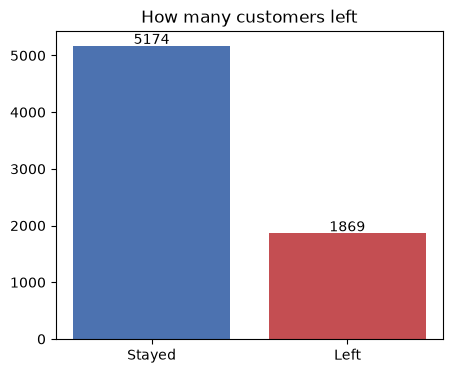

In [6]:
# The target, in counts and in percentage
counts = telco['Churn'].value_counts()
print(pd.DataFrame({'Customers': counts, 'Share %': (counts / len(telco) * 100).round(1)}))

plt.figure(figsize=(5, 4))
plt.bar(['Stayed', 'Left'], counts.values, color=['#4c72b0', '#c44e52'])
for i, value in enumerate(counts.values):
    plt.text(i, value + 30, str(value), ha='center')
plt.title('How many customers left')
plt.show()

The bar chart counts the two classes: 5,174 customers stayed and 1,869 left, 73.5 and 26.5 percent. The imbalance is milder than in a medical dataset but it still sets the floor of the evaluation: a model that answers "stays" for everyone is right 73.5 percent of the time, so an accuracy near 0.73 is the starting point and not a result. What the retention team needs is the share of the customers who leave that the model catches, which the course calls sensitivity or recall, and the evaluation is built around it.

## Data Exploration (CRISP-DM 2) and Data Preparation (CRISP-DM 3)

With a yes or no target the most readable exploration is the churn rate inside each value of each column. A rate of 3 percent against 43 percent is a fact a manager can act on, and it also says in advance which columns the network will lean on.

In [7]:
# Churn rate by the commercial columns
telco['churn'] = (telco['Churn'] == 'Yes').astype(int)
for column in ['Contract', 'InternetService', 'PaymentMethod', 'PaperlessBilling', 'SeniorCitizen']:
    rate = telco.groupby(column)['churn'].agg(['mean', 'count'])
    rate['mean'] = (rate['mean'] * 100).round(1)
    rate.columns = ['Churn rate %', 'Customers']
    print(rate)
    print()

                Churn rate %  Customers
Contract                               
Month-to-month          42.7       3875
One year                11.3       1473
Two year                 2.8       1695

                 Churn rate %  Customers
InternetService                         
DSL                      19.0       2421
Fiber optic              41.9       3096
No                        7.4       1526

                           Churn rate %  Customers
PaymentMethod                                     
Bank transfer (automatic)          16.7       1544
Credit card (automatic)            15.2       1522
Electronic check                   45.3       2365
Mailed check                       19.1       1612

                  Churn rate %  Customers
PaperlessBilling                         
No                        16.3       2872
Yes                       33.6       4171

               Churn rate %  Customers
SeniorCitizen                         
0                      23.6       5901


The contract is the strongest fact in the file. Customers on a month-to-month contract leave at 42.7 percent, on a one year contract at 11.3 and on a two year contract at 2.8, so a long contract divides the risk by fifteen. The type of internet is next: fiber optic customers leave at 41.9 percent, DSL at 19.0 and customers with no internet at 7.4, which is surprising for the faster service and suggests the fiber customers are either paying more or less happy with it. Paying by electronic check goes with a rate of 45.3 percent against 15 to 19 for every other method, and paperless billing with 33.6 against 16.3. Senior citizens leave at 41.7 percent against 23.6.

In [8]:
# Churn rate by the add-on services and the household columns
for column in ['TechSupport', 'OnlineSecurity', 'Partner', 'Dependents', 'gender']:
    rate = telco.groupby(column)['churn'].agg(['mean', 'count'])
    rate['mean'] = (rate['mean'] * 100).round(1)
    rate.columns = ['Churn rate %', 'Customers']
    print(rate)
    print()

                     Churn rate %  Customers
TechSupport                                 
No                           41.6       3473
No internet service           7.4       1526
Yes                          15.2       2044

                     Churn rate %  Customers
OnlineSecurity                              
No                           41.8       3498
No internet service           7.4       1526
Yes                          14.6       2019

         Churn rate %  Customers
Partner                         
No               33.0       3641
Yes              19.7       3402

            Churn rate %  Customers
Dependents                         
No                  31.3       4933
Yes                 15.5       2110

        Churn rate %  Customers
gender                         
Female          26.9       3488
Male            26.2       3555



Among the internet customers, the ones without technical support leave at 41.6 percent and the ones with it at 15.2, and online security shows the same split, 41.8 against 14.6. The 7.4 percent of the "No internet service" rows is the same group of 1,526 customers seen above. Customers with a partner leave at 19.7 percent against 33.0 without, and with dependents at 15.5 against 31.3. Gender changes nothing, 26.9 against 26.2, and it is the one column the exploration expects the network to ignore.

          Churn rate %  Customers
tenure                           
0 to 6            52.9       1481
7 to 12           35.9        705
13 to 24          28.7       1024
25 to 48          20.4       1594
49 to 72           9.5       2239

      tenure        MonthlyCharges        TotalCharges        
        mean median           mean median         mean  median
churn                                                         
0       37.6   38.0           61.3   64.4       2555.3  1683.6
1       18.0   10.0           74.4   79.6       1531.8   703.6


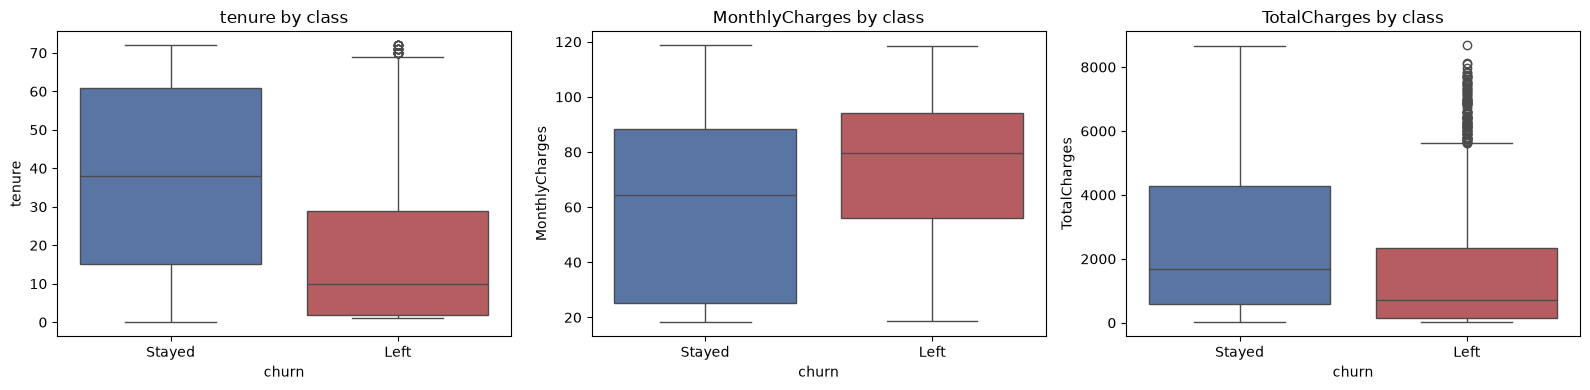

In [9]:
# Churn rate by how long the customer has stayed
TENURE_BANDS = [-1, 6, 12, 24, 48, 72]
BAND_LABELS = ['0 to 6', '7 to 12', '13 to 24', '25 to 48', '49 to 72']
by_tenure = telco.groupby(pd.cut(telco['tenure'], TENURE_BANDS, labels=BAND_LABELS), observed=True)['churn'].agg(['mean', 'count'])
by_tenure['mean'] = (by_tenure['mean'] * 100).round(1)
by_tenure.columns = ['Churn rate %', 'Customers']
print(by_tenure)

print()
print(telco.groupby('churn')[['tenure', 'MonthlyCharges', 'TotalCharges']].agg(['mean', 'median']).round(1))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, column in zip(axes, ['tenure', 'MonthlyCharges', 'TotalCharges']):
    sns.boxplot(data=telco, x='churn', y=column, ax=ax, hue='churn', palette=['#4c72b0', '#c44e52'], legend=False)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Stayed', 'Left'])
    ax.set_title(column + ' by class')
plt.tight_layout()
plt.show()

The tenure bands tell the story of the first months. Customers in their first six months leave at 52.9 percent, more than half, and the rate falls in every band until it reaches 9.5 percent past four years. The customers who left had a median tenure of 10 months against 38 for the ones who stayed.

The box plots show one box per class, where the box holds the middle half of the customers, the line inside is the median, the whiskers reach the values still close to the box and the dots beyond are the extremes. The tenure boxes barely overlap. The monthly bill runs the other way: the customers who left paid a median of 79.6 dollars against 64.4, so the ones leaving are the ones paying the most, which is consistent with the fiber optic finding. The total bill is lower for the ones who left, 704 against 1,684 dollars, but only because they stayed fewer months, since the total is roughly the monthly bill times the tenure.

In [10]:
print(telco[['tenure', 'MonthlyCharges', 'TotalCharges']].corr().round(3))

                tenure  MonthlyCharges  TotalCharges
tenure           1.000           0.248         0.826
MonthlyCharges   0.248           1.000         0.651
TotalCharges     0.826           0.651         1.000


The correlation, which runs from -1 to 1 and measures how close two columns are to a straight line, confirms that `TotalCharges` is mostly a product of the other two: 0.83 with tenure and 0.65 with the monthly bill. A linear model would need to worry about that overlap. A neural network is not read through its weights and does not suffer from it in the same way, so the column is kept, but it is fair to expect that it adds little the other two do not already say.

In [11]:
# Preparation. The identifier and the text target go, the eleven blank totals become 0,
# and every text column becomes 0 or 1 columns, dropping the first value of each as
# the reference the others are compared against
TOTAL_CHARGES_FILL = 0.0
telco['TotalCharges'] = telco['TotalCharges'].fillna(TOTAL_CHARGES_FILL)

TARGET = 'churn'
encoded = pd.get_dummies(telco.drop(columns=['customerID', 'Churn']), drop_first=True, dtype=int)
FEATURES = [c for c in encoded.columns if c != TARGET]
print("Number of predictors:", len(FEATURES))
print(FEATURES)
encoded.head()

Number of predictors: 30
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_No phone service', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_No internet service', 'OnlineSecurity_Yes', 'OnlineBackup_No internet service', 'OnlineBackup_Yes', 'DeviceProtection_No internet service', 'DeviceProtection_Yes', 'TechSupport_No internet service', 'TechSupport_Yes', 'StreamingTV_No internet service', 'StreamingTV_Yes', 'StreamingMovies_No internet service', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0,1,0,0,1,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,1,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,0,1,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,0,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0


The table is now entirely numeric, 30 predictors and the target. A column such as `Contract_Two year` is 1 for a customer on a two year contract and 0 otherwise, and a customer with 0 in both contract columns is on the reference value, month-to-month. The same reading applies to the payment method, with bank transfer as the reference, and to the internet service, with DSL as the reference.

In [12]:
# Stratified 75 / 25 split, so both sides keep the 26.5 percent of churn
X = encoded[FEATURES]
y = encoded[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)
print("Training customers:", len(X_train), "of which left:", int(y_train.sum()))
print("Test customers:", len(X_test), "of which left:", int(y_test.sum()))

Training customers: 5282 of which left: 1402
Test customers: 1761 of which left: 467


Training keeps 5,282 customers with 1,402 who left, and testing 1,761 customers with 467 who left. The split is stratified so the test set carries the same share of churn as the whole file, and the network is scored on exactly these 1,761 customers.

## Machine Learning Model (CRISP-DM 4: Modeling)

The network is scikit-learn's multilayer perceptron, fitted inside a pipeline whose first step standardizes every predictor, subtracting the mean and dividing by the standard deviation. Standardizing matters more for a network than for a tree, because the weights start at small random values and a predictor written in thousands, such as the total bill, would dominate every sum from the first step. The network has two hidden layers of 32 and 16 neurons with the relu activation, which passes positive sums through and turns negative sums to zero, and one output neuron with a sigmoid, which maps the final sum to a probability between 0 and 1. It is trained by backpropagation on the binary cross entropy, and training stops early when the loss on a slice of the training data held aside for that purpose stops improving, which is the guard against a network that memorises the training customers.

### Training the network

Training rounds before early stopping: 38
Best accuracy on the held-aside slice: 0.805


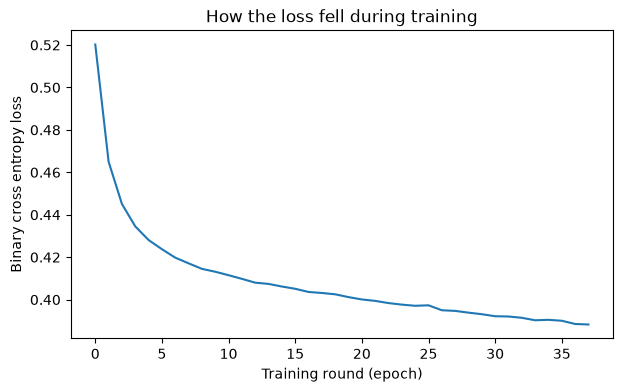

In [13]:
def build_network():
    return Pipeline([
        ('scale', StandardScaler()),
        ('network', MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=500,
                                  early_stopping=True, random_state=RANDOM_STATE)),
    ])

model = build_network().fit(X_train, y_train)
network = model.named_steps['network']
print("Training rounds before early stopping:", network.n_iter_)
print("Best accuracy on the held-aside slice: %.3f" % network.best_validation_score_)

plt.figure(figsize=(7, 4))
plt.plot(network.loss_curve_)
plt.xlabel('Training round (epoch)')
plt.ylabel('Binary cross entropy loss')
plt.title('How the loss fell during training')
plt.show()

The curve is the loss after each pass over the training customers, which the course calls an epoch. The loss is the binary cross entropy, which is large when the network gives a low probability to a customer who left or a high one to a customer who stayed, and it falls as backpropagation adjusts the weights. It drops fast in the first ten rounds and then flattens, and the training stopped after 38 rounds because the accuracy on the slice held aside, 0.805 at its best, stopped improving. A network allowed to keep going past that point would keep lowering this curve while getting worse on new customers.

Threshold                 0.500
Accuracy                  0.790
Sensitivity (recall)      0.529
Specificity               0.885
Precision                 0.624
F1                        0.572
AUC                       0.840
Leavers found           247.000
Leavers missed          220.000
False alarms            149.000
Name: Network, dtype: float64


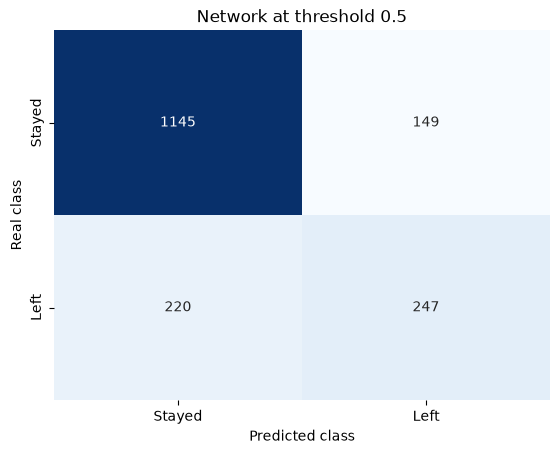

In [14]:
# Evaluation helper: confusion matrix, the rates and the AUC, at a chosen threshold
def evaluate(model, threshold, name):
    probability = model.predict_proba(X_test)[:, 1]
    predicted = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, predicted).ravel()
    return pd.Series({
        'Threshold': threshold,
        'Accuracy': accuracy_score(y_test, predicted),
        'Sensitivity (recall)': recall_score(y_test, predicted),
        'Specificity': tn / (tn + fp),
        'Precision': precision_score(y_test, predicted, zero_division=0),
        'F1': f1_score(y_test, predicted),
        'AUC': roc_auc_score(y_test, probability),
        'Leavers found': tp, 'Leavers missed': fn, 'False alarms': fp,
    }, name=name)

def show_confusion(model, threshold, title):
    predicted = (model.predict_proba(X_test)[:, 1] >= threshold).astype(int)
    matrix = confusion_matrix(y_test, predicted)
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Stayed', 'Left'], yticklabels=['Stayed', 'Left'])
    plt.xlabel('Predicted class')
    plt.ylabel('Real class')
    plt.title(title)
    plt.show()

DEFAULT_THRESHOLD = 0.5
print(evaluate(model, DEFAULT_THRESHOLD, 'Network').round(3))
show_confusion(model, DEFAULT_THRESHOLD, 'Network at threshold 0.5')

The confusion matrix has the real class in rows and the predicted class in columns: top left is customers correctly predicted to stay, bottom right is leavers correctly found, top right is false alarms and bottom left is leavers missed. Sensitivity, also called recall, is the share of the real leavers found. Specificity is the share of the stayers correctly left alone. Precision is the share of the flagged customers who really left. The AUC is the area under the ROC curve drawn next, 0.5 for a coin toss and 1 for a perfect ranking.

The network reaches an accuracy of 0.790 and an AUC of 0.840, so the ranking is decent, but at the threshold of 0.5 it finds 247 of the 467 leavers and misses 220, a sensitivity of 0.529. It errs on the side of "stays": with 149 false alarms its precision of 0.624 is good, but a retention team working from this list would never hear about nearly half the customers who are about to go. That is the imbalance at work, since the network saw three stayers for every leaver and learned to be cautious about the minority.

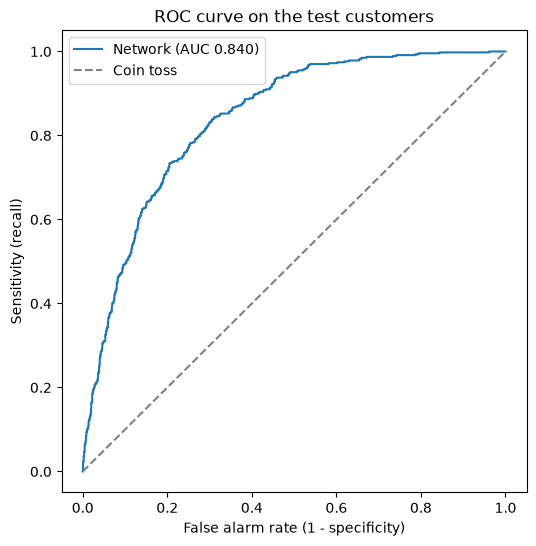

In [15]:
# ROC curve of the network on the test customers
probability = model.predict_proba(X_test)[:, 1]
false_alarm_rate, sensitivity, _ = roc_curve(y_test, probability)

plt.figure(figsize=(6, 6))
plt.plot(false_alarm_rate, sensitivity, label='Network (AUC %.3f)' % roc_auc_score(y_test, probability))
plt.plot([0, 1], [0, 1], linestyle='--', color='grey', label='Coin toss')
plt.xlabel('False alarm rate (1 - specificity)')
plt.ylabel('Sensitivity (recall)')
plt.title('ROC curve on the test customers')
plt.legend()
plt.show()

The ROC curve traces every threshold at once: each point is the sensitivity the network reaches, vertically, at the false alarm rate it pays for it, horizontally, and a curve closer to the top left corner ranks customers better. The dashed diagonal is a coin toss. The network's curve rises steeply at first, so the customers it is most sure about really do leave, and its area of 0.840 says that a random leaver gets a higher probability than a random stayer 84 times in 100. The threshold of 0.5 is only one point on this curve, and the next cell walks along it.

In [16]:
# How the network behaves at several thresholds
THRESHOLDS = [0.3, 0.4, 0.5, 0.6, 0.7]
sweep = pd.concat([evaluate(model, t, 'threshold %.1f' % t) for t in THRESHOLDS], axis=1).T
print(sweep.round(3).to_string())

               Threshold  Accuracy  Sensitivity (recall)  Specificity  Precision     F1   AUC  Leavers found  Leavers missed  False alarms
threshold 0.3        0.3     0.762                 0.745        0.768      0.537  0.624  0.84          348.0           119.0         300.0
threshold 0.4        0.4     0.784                 0.664        0.828      0.582  0.620  0.84          310.0           157.0         223.0
threshold 0.5        0.5     0.790                 0.529        0.885      0.624  0.572  0.84          247.0           220.0         149.0
threshold 0.6        0.6     0.789                 0.398        0.930      0.674  0.501  0.84          186.0           281.0          90.0
threshold 0.7        0.7     0.767                 0.212        0.967      0.697  0.325  0.84           99.0           368.0          43.0


Each row is the same network with a different cut on its probability; the AUC does not move because the ranking is the same. Lowering the threshold to 0.3 finds 348 of the 467 leavers, 101 more than at 0.5, at the price of 300 false alarms instead of 149, and the accuracy falls from 0.790 to 0.762. Raising it to 0.7 flags only 43 stayers but misses 368 leavers. The default of 0.5, with 247 found, 220 missed and 149 false alarms, is the most accurate cut and the one kept; a retention team that can afford to call a quarter of its customers would be better served by 0.3. The threshold is a business decision that depends on the cost of a call against the value of a saved customer, so the probability itself is what gets stored and the API can apply whichever cut the company chooses.

## Evaluation (CRISP-DM 5)

The kept model is the network at a threshold of 0.5. Its full report on the test customers follows.

In [17]:
print(evaluate(model, DEFAULT_THRESHOLD, 'Network').round(3))
print()
print(classification_report(y_test, model.predict(X_test), target_names=['Stayed', 'Left']))

Threshold                 0.500
Accuracy                  0.790
Sensitivity (recall)      0.529
Specificity               0.885
Precision                 0.624
F1                        0.572
AUC                       0.840
Leavers found           247.000
Leavers missed          220.000
False alarms            149.000
Name: Network, dtype: float64

              precision    recall  f1-score   support

      Stayed       0.84      0.88      0.86      1294
        Left       0.62      0.53      0.57       467

    accuracy                           0.79      1761
   macro avg       0.73      0.71      0.72      1761
weighted avg       0.78      0.79      0.78      1761



The report lists, for each class, the precision, the recall, their combination F1 and the support, which is the number of test customers in the class. For the customers who left, the network reaches a recall of 0.53 with a precision of 0.62, and for the ones who stayed a recall of 0.88 with a precision of 0.84. The F1 of the leavers, 0.57, is the number that balances finding them against flagging the wrong ones, and the weighted F1 of 0.78 is pulled up by the majority class.

The accuracy of 0.790 is 5.5 points above the 0.735 of always answering "stays", and the AUC of 0.840 says the probabilities rank the customers well. The weak number is the recall of the leavers: at the threshold of 0.5 the network misses 220 of the 467, because it saw three stayers for every leaver and learned to be cautious about the minority. The threshold sweep above shows that this is a property of the cut and not of the ranking, since the same network at 0.3 finds three leavers out of four.

## Results and Conclusion (CRISP-DM 6: Deployment)

The model kept is a multilayer perceptron with two hidden layers of 32 and 16 neurons, trained by backpropagation on the training set as it is and applied at a threshold of 0.5 on 30 encoded predictors. On the 1,761 test customers it reaches an AUC of 0.840, an accuracy of 0.790, a sensitivity of 0.529, a specificity of 0.885, a precision of 0.624 and an F1 of 0.572. In the units of the problem, it names 247 of the 467 customers who leave and sends the retention team after 149 who would have stayed.

Two limitations are stated plainly. First, the network favours the majority answer: at the default cut it misses nearly half the leavers, and the threshold sweep shows that the company can trade accuracy for recall by lowering the cut, finding 348 leavers at 0.3 in exchange for twice the false alarms. Second, the precision of 0.62 means that about four customers in ten on the list would not have left, so the list is a set of customers worth a call, not a prediction of who will cancel. The pipeline, which includes the scaler and the network, is saved below with its 30 predictor names, the threshold and the fill value of the total bill, so the REST API can build the same columns from a customer's record and predict without training again.

In [18]:
bundle = {
    'model': model,
    'features': FEATURES,
    'target': TARGET,
    'threshold': DEFAULT_THRESHOLD,
    'total_charges_fill': TOTAL_CHARGES_FILL,
}
MODEL_PATH = os.path.join(MODELS_DIR, 'telecom_churn_classification.joblib')
joblib.dump(bundle, MODEL_PATH)
print("Saved to", MODEL_PATH)

Saved to ../../models/telecom_churn_classification.joblib


In [19]:
# Reload and score one customer by hand: three months in, month-to-month contract, fiber optic,
# no security or support add-ons, paperless billing, electronic check, 85 dollars a month
loaded = joblib.load(MODEL_PATH)
customer = pd.DataFrame([dict.fromkeys(loaded['features'], 0)])
customer.loc[0, ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']] = [0, 3, 85.0, 255.0]
customer.loc[0, ['PhoneService_Yes', 'InternetService_Fiber optic', 'StreamingTV_Yes',
                 'PaperlessBilling_Yes', 'PaymentMethod_Electronic check']] = 1
probability = loaded['model'].predict_proba(customer)[0, 1]
print("Probability of leaving: %.3f" % probability)
print("Flagged for the retention team:", bool(probability >= loaded['threshold']))

Probability of leaving: 0.769
Flagged for the retention team: True


The reloaded pipeline gives this new fiber optic customer on a month-to-month contract paying by electronic check a probability of 0.77, well above the threshold, so the customer would be on the retention list, which is what the exploration's rates of 43, 42 and 45 percent for those three facts, compounded by a tenure under six months, imply. The API repeats this call: build the 30 columns from the customer's record, predict the probability and compare it with the stored threshold.